# Lecture 12 | RNN · LSTM · Attention · GPT


## 0. 준비: 문장 2개를 숫자 상자로 생각하기 (1분)
입력 `(2, 5, 3)` = 샘플 2개 × 순서 5칸 × 특징 3개. 학습하지 않은 모델의 shape만 확인합니다.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# 같은 예시를 다시 실행하기 위한 설정
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)
plt.rcParams['font.family'] = 'DejaVu Sans'

x = torch.randn(2, 5, 3)
rnn = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
lstm = nn.LSTM(input_size=3, hidden_size=4, batch_first=True)
rnn_out, rnn_h = rnn(x)
lstm_out, (lstm_h, lstm_c) = lstm(x)
print('Input:       ', tuple(x.shape))
print('RNN output:  ', tuple(rnn_out.shape))
print('RNN final h: ', tuple(rnn_h.shape))
print('LSTM output: ', tuple(lstm_out.shape))
print('LSTM final h:', tuple(lstm_h.shape))
print('LSTM final c:', tuple(lstm_c.shape))

Input:        (2, 5, 3)
RNN output:   (2, 5, 4)
RNN final h:  (1, 2, 4)
LSTM output:  (2, 5, 4)
LSTM final h: (1, 2, 4)
LSTM final c: (1, 2, 4)


## 1. LSTM 예측: 과거 20개 센서값으로 다음 1개 맞히기 (약 4분)
원본의 사인파 + 랜덤 노이즈 데이터를 유지했습니다. 실험 데이터가 아닌 교육용 가상 신호입니다. 미래 시점을 예측하는 문제이므로 **시간 순서대로** 훈련/테스트를 구분합니다. 테스트는 각 시점에서 실제로 관측된 과거 20개를 이용한 **one-step forecasting**입니다. 미래 전체를 한 번에 예측한 것이 아닙니다.

Train: (784, 20, 1) -> (784, 1)
Test:  (196, 20, 1) -> (196, 1)


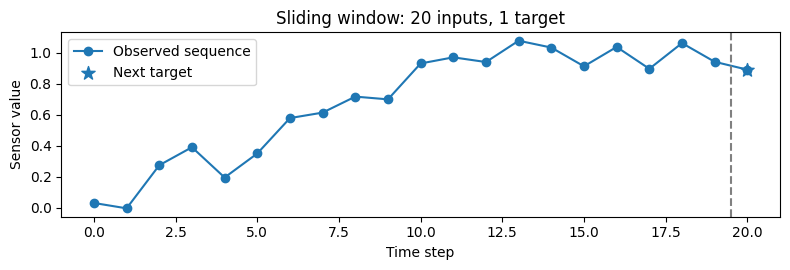

In [4]:
rng = np.random.default_rng(42)
t = np.linspace(0, 100, 1000)
sensor_data = np.sin(t) + rng.normal(0, 0.1, len(t))
seq_length = 20

# 예시: 1~20번째 값 -> 21번째 값, 2~21번째 값 -> 22번째 값
X = np.array([sensor_data[i:i+seq_length] for i in range(len(t)-seq_length)])
y = sensor_data[seq_length:]
X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)
train_size = int(len(X) * 0.8)
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]
print('Train:', tuple(X_train.shape), '->', tuple(y_train.shape))
print('Test: ', tuple(X_test.shape), '->', tuple(y_test.shape))

plt.figure(figsize=(8, 2.8))
plt.plot(np.arange(21), sensor_data[:21], 'o-', label='Observed sequence')
plt.scatter(20, sensor_data[20], s=100, marker='*', label='Next target')
plt.axvline(19.5, linestyle='--', color='gray')
plt.xlabel('Time step'); plt.ylabel('Sensor value')
plt.title('Sliding window: 20 inputs, 1 target'); plt.legend(); plt.tight_layout(); plt.show()

### 1-2. 실제 LSTM 학습
`LSTM`은 20개 시점을 읽어 은닉 상태를 만들고 `Linear`는 마지막 은닉 상태를 숫자 하나로 바꿉니다. `MSELoss`는 다음 센서값의 실제값과 예측값을 비교합니다. 원본처럼 full-batch 학습을 사용합니다(1 epoch = 1 update).

Epoch  30: train MSE = 0.0178
Epoch  60: train MSE = 0.0162
Epoch  90: train MSE = 0.0142
Epoch 120: train MSE = 0.0126
Epoch 150: train MSE = 0.0118


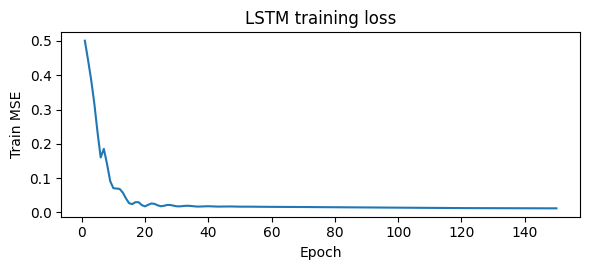

In [5]:
class TimeSeriesLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)
    def forward(self, x):
        states, _ = self.lstm(x)
        return self.fc(states[:, -1, :])

torch.manual_seed(42)
model = TimeSeriesLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []
num_epochs = 150
model.train()
for epoch in range(num_epochs):
    optimizer.zero_grad()
    pred = model(X_train)
    loss = criterion(pred, y_train)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (epoch+1) % 30 == 0:
        print(f'Epoch {epoch+1:3d}: train MSE = {loss.item():.4f}')

plt.figure(figsize=(6, 2.8))
plt.plot(range(1, num_epochs+1), loss_history)
plt.xlabel('Epoch'); plt.ylabel('Train MSE'); plt.title('LSTM training loss'); plt.tight_layout(); plt.show()

### 1-3. 처음 보는 시간 구간에서 평가
가장 최근 관측값을 그대로 다음 값으로 예측하는 persistence baseline과 비교합니다. 낮은 test MSE가 항상 다른 종류의 시계열에서도 잘 작동함을 의미하지는 않습니다.

LSTM test MSE:        0.0117
Last-value baseline:  0.0234


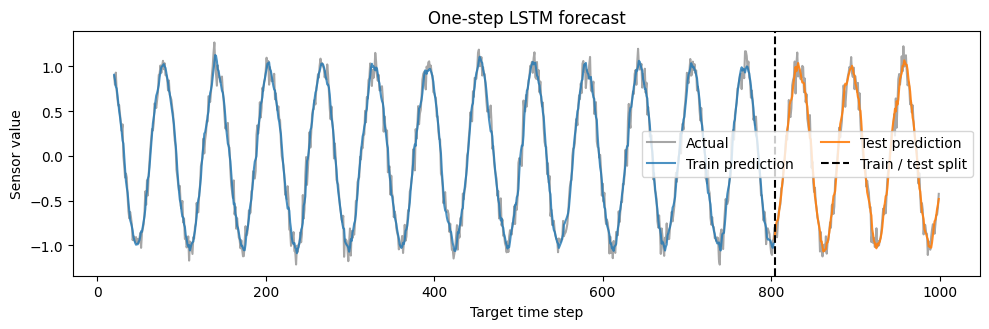

In [6]:
model.eval()
with torch.no_grad():
    train_predict = model(X_train).squeeze(-1).numpy()
    test_predict = model(X_test).squeeze(-1).numpy()
    test_mse = criterion(model(X_test), y_test).item()
    baseline_mse = criterion(X_test[:, -1, :], y_test).item()
print(f'LSTM test MSE:        {test_mse:.4f}')
print(f'Last-value baseline:  {baseline_mse:.4f}')

# 예측값의 가로축을 실제 목표 시점과 정확히 정렬
idx = np.arange(seq_length, len(t))
plt.figure(figsize=(10, 3.4))
plt.plot(idx, y.squeeze(-1).numpy(), color='gray', alpha=.7, label='Actual')
plt.plot(idx[:train_size], train_predict, alpha=.8, label='Train prediction')
plt.plot(idx[train_size:], test_predict, alpha=.9, label='Test prediction')
plt.axvline(idx[train_size], color='black', linestyle='--', label='Train / test split')
plt.xlabel('Target time step'); plt.ylabel('Sensor value'); plt.title('One-step LSTM forecast'); plt.legend(ncol=2); plt.tight_layout(); plt.show()

## 2. Q / K / V: 직접 계산하는 Attention (3분)
예시로 토큰 3개, Query 1개, 2차원 Key와 2차원 Value를 정합니다. **학습된 언어모델의 실제 attention이 아니라 계산 원리를 보여 주는 숫자**입니다. Q와 K로 점수를 만들고, softmax 후 그 비율로 V를 섞습니다.

Scaled scores: [[2.828 1.414 0.   ]]
Weights:       [[0.768 0.187 0.045]]
Row sum:       [1.]
Mixed value:   [[7.861 2.048]]


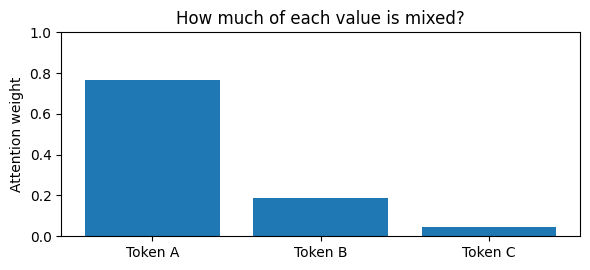

In [7]:
Q = np.array([[2., 0.]])
K = np.array([[2., 0.], [1., 0.], [0., 1.]])
V = np.array([[10., 0.], [0., 10.], [4., 4.]])

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / exp_x.sum(axis=-1, keepdims=True)

scores = Q @ K.T / np.sqrt(K.shape[-1])
weights = softmax(scores)
output = weights @ V
print('Scaled scores:', scores.round(3))
print('Weights:      ', weights.round(3))
print('Row sum:      ', weights.sum(axis=-1))
print('Mixed value:  ', output.round(3))
plt.figure(figsize=(6, 2.8))
plt.bar(['Token A', 'Token B', 'Token C'], weights[0])
plt.ylim(0, 1); plt.ylabel('Attention weight'); plt.title('How much of each value is mixed?'); plt.tight_layout(); plt.show()

## 3. Causal mask: 미래 토큰은 0으로 (3분)
원본의 5개 시점, 16차원 입력 예제를 보존하되 마스크 적용 전후를 같은 눈금으로 비교합니다. 행은 Query(보는 위치), 열은 Key(참고 대상). **마스크는 softmax 전에 미래 점수를 -inf로 설정**합니다. 랜덤 초기화된 projection이므로 언어 관계를 학습한 예제가 아닙니다.

Input shape: (1, 5, 16)
Score shape: (1, 5, 5)
Output shape: (1, 5, 16)
Row sums: [[1. 1. 1. 1. 1.]]


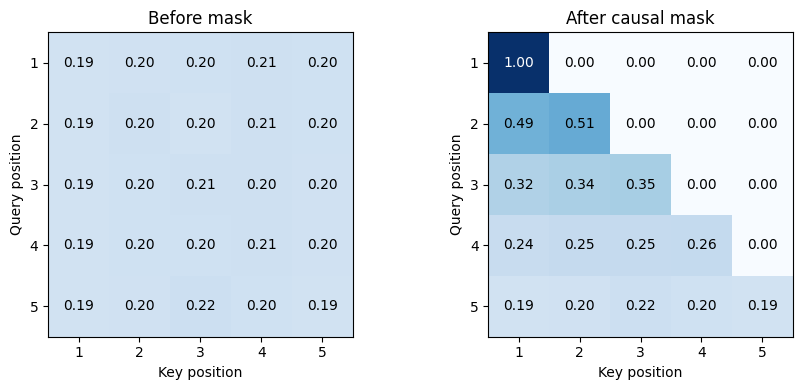

In [8]:
torch.manual_seed(42)
seq_length, embed_dim = 5, 16
tokens = torch.rand(1, seq_length, embed_dim)
W_q = nn.Linear(embed_dim, embed_dim, bias=False)
W_k = nn.Linear(embed_dim, embed_dim, bias=False)
W_v = nn.Linear(embed_dim, embed_dim, bias=False)
Q, K, V = W_q(tokens), W_k(tokens), W_v(tokens)
attention_scores = Q @ K.transpose(-2, -1) / np.sqrt(embed_dim)
allowed = torch.tril(torch.ones(seq_length, seq_length, dtype=torch.bool))
masked_scores = attention_scores.masked_fill(~allowed, float('-inf'))
A_before = F.softmax(attention_scores, dim=-1)
A_after = F.softmax(masked_scores, dim=-1)
context = A_after @ V
print('Input shape:', tuple(tokens.shape))
print('Score shape:', tuple(attention_scores.shape))
print('Output shape:', tuple(context.shape))
print('Row sums:', A_after.sum(dim=-1).detach().numpy().round(4))
assert torch.all(A_after[0][~allowed] == 0)

# 동일한 색상 범위로 두 그림 비교
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, a, title in zip(axes, [A_before, A_after], ['Before mask', 'After causal mask']):
    mat = a[0].detach().numpy()
    im = ax.imshow(mat, cmap='Blues', vmin=0, vmax=1)
    for i in range(seq_length):
        for j in range(seq_length):
            ax.text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center', color='white' if mat[i,j]>.6 else 'black')
    ax.set_xticks(range(5), range(1,6)); ax.set_yticks(range(5), range(1,6))
    ax.set_xlabel('Key position'); ax.set_ylabel('Query position'); ax.set_title(title)
fig.tight_layout(); plt.show()

## 4. Multi-head Attention: 두 관점 (1분 30초)
8차원 표현을 2개 head(각각 4차원)로 사용합니다. head별 가중치를 확인하기 위해 `average_attn_weights=False`를 지정합니다. 미래를 보지 않는 mask를 적용합니다. 랜덤 초기화라 head에 문법적 의미를 부여할 수는 없습니다.

Input:         (1, 4, 8)
Output:        (1, 4, 8)
Head weights:  (1, 2, 4, 4)


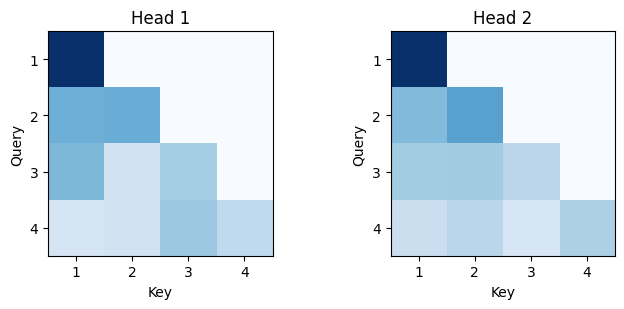

In [9]:
torch.manual_seed(13)
tokens_mh = torch.randn(1, 4, 8)
attn = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
# MultiheadAttention의 bool mask는 True가 차단 위치입니다.
blocked = torch.triu(torch.ones(4, 4, dtype=torch.bool), diagonal=1)
out, head_weights = attn(tokens_mh, tokens_mh, tokens_mh,
                         attn_mask=blocked, average_attn_weights=False)
print('Input:        ', tuple(tokens_mh.shape))
print('Output:       ', tuple(out.shape))
print('Head weights: ', tuple(head_weights.shape))
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for h, ax in enumerate(axes):
    ax.imshow(head_weights[0,h].detach().numpy(), cmap='Blues', vmin=0, vmax=1)
    ax.set_title(f'Head {h+1}'); ax.set_xlabel('Key'); ax.set_ylabel('Query')
    ax.set_xticks(range(4), range(1,5)); ax.set_yticks(range(4), range(1,5))
fig.tight_layout(); plt.show()

## 5. 다음 토큰 선택: temperature (2분 30초)
가상 프롬프트 'The battery' 뒤에 오는 후보에 임의의 logits를 줍니다. GPT 전체를 학습한 결과는 아닙니다. 같은 logits에서 온도만 바꾸며 분포와 샘플을 비교합니다. temperature가 높다고 항상 더 좋은 답이 나오는 것은 아닙니다.

T=0.5: {np.str_('works'): np.float64(0.875), np.str_('stores'): np.float64(0.118), np.str_('failed'): np.float64(0.006), np.str_('sings'): np.float64(0.0)}
  8 sampled tokens: works, works, works, works, works, stores, works, works
T=1.0: {np.str_('works'): np.float64(0.681), np.str_('stores'): np.float64(0.251), np.str_('failed'): np.float64(0.056), np.str_('sings'): np.float64(0.012)}
  8 sampled tokens: works, works, works, stores, works, stores, works, works
T=2.0: {np.str_('works'): np.float64(0.493), np.str_('stores'): np.float64(0.299), np.str_('failed'): np.float64(0.141), np.str_('sings'): np.float64(0.067)}
  8 sampled tokens: stores, works, failed, stores, stores, works, sings, failed


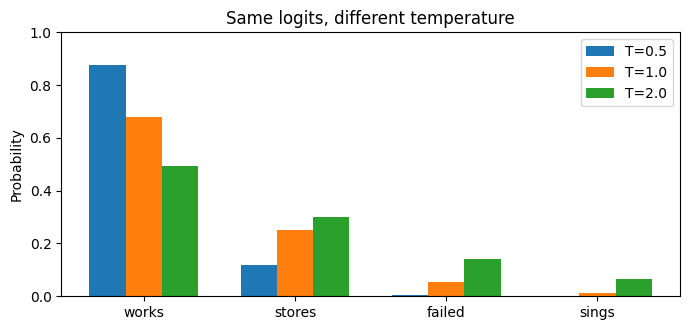

In [10]:
vocab = np.array(['works', 'stores', 'failed', 'sings'])
logits = np.array([3.0, 2.0, 0.5, -1.0])
Ts = [0.5, 1.0, 2.0]
rng = np.random.default_rng(42)
plt.figure(figsize=(7, 3.4))
for i, T in enumerate(Ts):
    probs = softmax(logits / T)
    print(f'T={T}:', dict(zip(vocab, probs.round(3))))
    print('  8 sampled tokens:', ', '.join(rng.choice(vocab, size=8, p=probs)))
    plt.bar(np.arange(len(vocab)) + (i-1)*.24, probs, width=.24, label=f'T={T}')
plt.xticks(range(len(vocab)), vocab); plt.ylim(0, 1)
plt.ylabel('Probability'); plt.title('Same logits, different temperature'); plt.legend(); plt.tight_layout(); plt.show()

## 선택 실습 | 실제 한국어 GPT-2 이어쓰기 (수업 전 실행 권장)
원본 KoGPT2 예제를 유지합니다. 아래 `RUN_KOGPT2 = True`로 바꾸면 모델을 다운로드합니다. 인터넷과 transformers 설치가 필요합니다. Colab의 모델 다운로드 및 호환성은 환경에 따라 달라질 수 있습니다. 기본값 False에서는 다운로드하지 않습니다. 이 모델은 대화형 instruction-tuned ChatGPT가 아니라 **텍스트 이어쓰기 모델**입니다. 출력이 사실을 보장하지 않습니다.

In [14]:
# !pip install transformers torch

import torch
from transformers import PreTrainedTokenizerFast, GPT2LMHeadModel

print("GPT 모델 및 토크나이저 로딩 중... (최초 실행 시 다운로드에 시간이 걸릴 수 있습니다)")
# 1. SKT에서 공개한 한국어 GPT-2 모델 로드
tokenizer = PreTrainedTokenizerFast.from_pretrained("skt/kogpt2-base-v2", bos_token='</s>', eos_token='</s>', unk_token='<unk>', pad_token='<pad>', mask_token='<mask>')
model = GPT2LMHeadModel.from_pretrained("skt/kogpt2-base-v2")
model.eval()

# 2. 시작 문장 (Prompt) 입력
prompt_text = "인공지능은 데이터를 활용하여"
print(f"\n[입력된 프롬프트]\n{prompt_text}\n")

# 3. 텍스트를 모델이 연산할 수 있는 숫자(Token ID)로 변환
input_ids = tokenizer.encode(prompt_text, return_tensors='pt')

# 4. GPT 텍스트 생성 (Autoregressive Generation)
# 앞서 배운 Masked Self-Attention을 활용하여, 현재까지의 단어만 보고 다음 단어를 예측하는 과정을 반복합니다.
with torch.no_grad():
    generated_ids = model.generate(
        input_ids,
        max_length=60,            # 생성할 최대 길이 (단어 수)
        repetition_penalty=1.2,   # 같은 단어가 반복되는 것을 방지하는 페널티
        do_sample=True,           # 무작위성을 부여하여 창의적인 답변 유도
        temperature=0.7,          # 생성의 다양성 조절 (낮을수록 보수적, 높을수록 창의적)
        top_k=50                  # 확률이 높은 상위 50개 단어 중에서만 다음 단어 선택
    )

# 5. 생성된 숫자(Token ID)를 다시 사람이 읽을 수 있는 텍스트로 디코딩
generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

print("[GPT 생성 결과]")
print("-" * 50)
print(generated_text)
print("-" * 50)

GPT 모델 및 토크나이저 로딩 중... (최초 실행 시 다운로드에 시간이 걸릴 수 있습니다)


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: skt/kogpt2-base-v2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



[입력된 프롬프트]
인공지능은 데이터를 활용하여

[GPT 생성 결과]
--------------------------------------------------
인공지능은 데이터를 활용하여 고객의 요구사항을 정확히 파악해 맞춤형 서비스를 제공할 수 있는 분야다.
이런 측면에서 볼 때 LG전자는 이번 협약으로 고객들이 필요한 정보를 간편하게 얻을 수 있게 됐다.
특히 빅데이터 분석을 통해 고객이 원하는 서비스 유형을 선택할 수 있도록 하고 이를 기반으로 고객들의 만족도를
--------------------------------------------------


### 핵심 정리
- RNN/LSTM: 이전 상태를 다음 시점으로 전달합니다.
- Attention: Q·K로 점수, softmax로 가중치, V를 가중합합니다.
- Causal mask: 미래 Key를 가립니다.
- GPT: 다음 토큰 분포를 만들고 한 토큰씩 생성합니다.